# Inicio del proyecto con UCI HAR 6 actividades

Características de sensores; investiguen el aporte de la información del giroscopio.

Este notebook carga los datos y explica su estructura. **No es una solución del proyecto.** Completen las secciones de investigación del final. Trabajen en Colab gratuito.

Fuente: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

## 1. Cargar los datos
Descompriman la entrega en su computador y abran este `.ipynb` en Colab. Ejecuten la siguiente celda y suban **ML_2026_11_10_UCI_HAR_6_actividades_DATOS.zip**, ubicado junto a este notebook. No suban el paquete general ni vuelvan a descargar la fuente original. La carga no necesita GPU.

In [1]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

archivo = Path('data/UCI_HAR_6_actividades.zip')
if not archivo.exists():
    from google.colab import files
    subidos = files.upload()
    if archivo.name not in subidos:
        raise ValueError("Sube el ZIP de DATOS que indica este notebook, con su nombre original.")

paquete = zipfile.ZipFile(archivo)
def leer_auxiliar(nombre):
    """Devuelve bytes de un archivo auxiliar incluido en este ZIP."""
    return io.BytesIO(paquete.read(nombre))

datos = np.load(leer_auxiliar('ML_2026_11_10_UCI_HAR_6_actividades_arrays.npz'), allow_pickle=False)
X, y = datos['X'], datos['y']
ids, split, nombres = datos['ids'], datos['split'], datos['names']
print('X:', X.shape, X.dtype, '| y:', y.shape)
print(dict(enumerate(nombres)))

X: (10299, 561) float32 | y: (10299,)
{0: np.str_('Caminar'), 1: np.str_('Subir escaleras'), 2: np.str_('Bajar escaleras'), 3: np.str_('Sentarse'), 4: np.str_('Estar de pie'), 5: np.str_('Acostarse')}


In [2]:
print("Eindeutige Splits:", np.unique(split, return_counts=True))
print("Anzahl eindeutiger Probanden (ids):", len(np.unique(ids)), "->", np.unique(ids))
print("Klassenverteilung in y:", np.unique(y, return_counts=True))
print("NaN-Werte in X:", np.isnan(X).sum())

Eindeutige Splits: (array(['test', 'train', 'val'], dtype='<U5'), array([2947, 5176, 2176]))
Anzahl eindeutiger Probanden (ids): 10299 -> [    0     1     2 ... 10296 10297 10298]
Klassenverteilung in y: (array([0, 1, 2, 3, 4, 5]), array([1722, 1544, 1406, 1777, 1906, 1944]))
NaN-Werte in X: 0


## 2. Respetar las particiones
Cada fila de `X`, `y`, `ids` y `split` corresponde a la misma observación. `y` es una etiqueta entera desde cero. Los identificadores y las etiquetas no son predictores. Usen `train` para aprender parámetros y transformaciones, `val` para elegir modelos y `test` para la evaluación final. La tabla de tamaños no evalúa ningún modelo.

In [3]:
# Identificar los ejemplos de cada partición
train = split == 'train'
val = split == 'val'
test = split == 'test'

# Separar las características
X_train = X[train]
X_val = X[val]
X_test = X[test]

# Separar las etiquetas
y_train = y[train]
y_val = y[val]
y_test = y[test]

# Mostrar el tamaño de cada conjunto
print("Ejemplos de entrenamiento:", len(y_train))
print("Ejemplos de validación:", len(y_val))
print("Ejemplos de test:", len(y_test))

Ejemplos de entrenamiento: 5176
Ejemplos de validación: 2176
Ejemplos de test: 2947


## 3. Escalar sin fuga de información
Las características ya están calculadas. El ejemplo ajusta un escalador **solo con entrenamiento** y transforma después validación y test. No vuelvan a ajustar el escalador sobre el conjunto completo. Para cada representación alternativa ajusten su propio escalador de entrenamiento. Los árboles no requieren este escalado.

In [4]:
from sklearn.preprocessing import StandardScaler
escalador = StandardScaler()
X_train_scaled = escalador.fit_transform(X_train).astype('float32')
X_val_scaled = escalador.transform(X_val).astype('float32')
X_test_scaled = escalador.transform(X_test).astype('float32')
print('Entrada preparada para MLP:', X_train_scaled.shape)

Entrada preparada para MLP: (5176, 561)


### Personas y grupos de variables
Las ventanas de una persona permanecen en una sola partición. Este control es esencial porque las ventanas no son observaciones independientes. Las 561 variables oficiales ya resumen señales; no estamos entrenando una red temporal. El ejemplo selecciona variables cuyo nombre contiene `Acc` y no `Gyro`; revisen la lista y el archivo de descripción para justificar qué consideran aceleración y cómo tratan variables mixtas.

In [5]:
# Identificador de la persona correspondiente a cada ejemplo
subject = datos['subject']

# Personas presentes en cada partición
personas_train = np.unique(subject[train])
personas_val = np.unique(subject[val])
personas_test = np.unique(subject[test])

print("Personas en entrenamiento:", personas_train)
print("Personas en validación:", personas_val)
print("Personas en test:", personas_test)

# Estas tres listas deben salir vacías
print("Personas compartidas entre train y val:",
      np.intersect1d(personas_train, personas_val))

print("Personas compartidas entre train y test:",
      np.intersect1d(personas_train, personas_test))

print("Personas compartidas entre val y test:",
      np.intersect1d(personas_val, personas_test))

Personas en entrenamiento: [ 1  3  5  7  8 11 14 16 17 19 21 22 25 28 29]
Personas en validación: [ 6 15 23 26 27 30]
Personas en test: [ 2  4  9 10 12 13 18 20 24]
Personas compartidas entre train y val: []
Personas compartidas entre train y test: []
Personas compartidas entre val y test: []


## 4. Desarrollar la investigación
Completen las siguientes secciones con texto, código y resultados. Consulten el enunciado y las rúbricas. No es necesario aplicar todas las ideas propuestas. Seleccionen una pregunta y una comparación que puedan justificar.

## Pregunta e hipótesis
¿Qué quieren averiguar y qué cambio observable esperan?

Research Question:
How much does adding gyroscope and angular velocity features (561 features total) improve human activity classification performance compared to using accelerometer-only features (343 features) in a Multi-Layer Perceptron (MLP)?

Hypothesis:
Including gyroscope features will measurably improve overall test accuracy and macro F1-score compared to the accelerometer-only baseline. Specifically, we expect the largest gains in:

1. Dynamic locomotion activities (Caminar, Subir escaleras, Bajar escaleras), where angular velocity captures rotational torso and leg movements that linear acceleration alone cannot fully distinguish.

2. Fine-grained postural distinctions (Sentarse vs. Estar de pie), where subtle orientation changes help reduce confusion, whereas Acostarse is already well separated by gravity acceleration alone.

Evaluation Criterion:
Our hypothesis will be supported if the MLP trained on all 561 features achieves a higher test macro F1-score and reduces false positives/negatives in the confusion matrix for dynamic activities and Sentarse/Estar de pie compared to the identical MLP trained on the 343 accelerometer features.

#### We want to investigate if the Gyro data improves the movement detection and by how much. The hypothesis is that including the Gyro data should improve the movement classification especially between standing and lying 

## Exploración y decisiones
¿Qué evidencia justifica su representación, preprocesamiento y métricas?

In [6]:
acc_ranges = [
    range(1, 121),    # tBodyAcc, tGravityAcc, tBodyAccJerk (1–120)
    range(201, 240),  # tBodyAccMag, tGravityAccMag, tBodyAccJerkMag (201–239)
    range(266, 424),  # fBodyAcc, fBodyAccJerk (266–423)
    range(503, 529),  # fBodyAccMag, fBodyBodyAccJerkMag (503–528)
    # Optional: reine Acc-Winkel am Ende (555, 556, 560, 561)
]

# In 0-basierte Python-Indizes umwandeln
acc_idx = [col - 1 for r in acc_ranges for col in r]

X_train_acc = X_train_scaled[:, acc_idx]
X_val_acc = X_val_scaled[:, acc_idx]
X_test_acc = X_test_scaled[:, acc_idx]
print("Shape von X_train_acc:", X_train_acc.shape)

Shape von X_train_acc: (5176, 343)


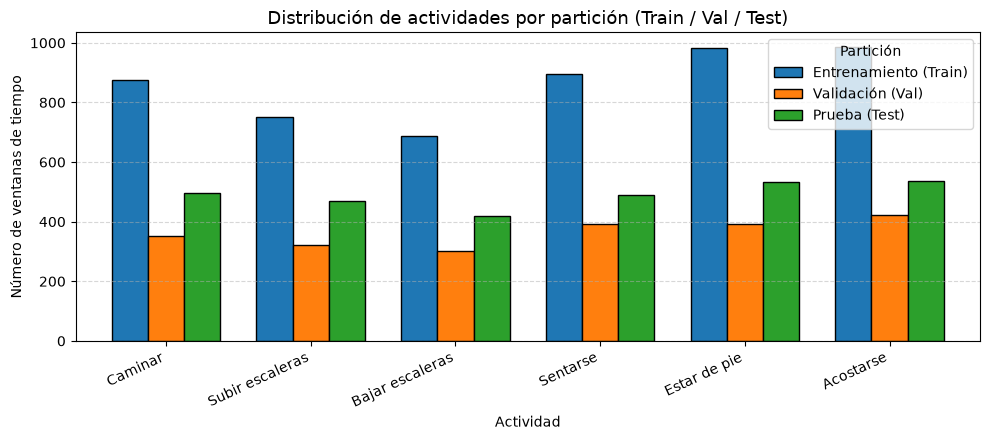

In [7]:
df_dist = pd.DataFrame({
    'Entrenamiento (Train)': pd.Series(y_train).value_counts().sort_index(),
    'Validación (Val)':      pd.Series(y_val).value_counts().sort_index(),
    'Prueba (Test)':         pd.Series(y_test).value_counts().sort_index(),
})
df_dist.index = nombres

ax = df_dist.plot(kind='bar', figsize=(10, 4.5), edgecolor='black', width=0.75)
plt.title('Distribución de actividades por partición (Train / Val / Test)', fontsize=13)
plt.ylabel('Número de ventanas de tiempo')
plt.xlabel('Actividad')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Partición')
plt.tight_layout()
plt.show()

### Interpretation: 
The six target activities are well balanced across the training, validation, and test partitions, with each activity representing roughly 14–19% of the samples in every split. Because there is no severe class imbalance, standard accuracy and macro-averaged F1-score are both reliable evaluation metrics without requiring class weighting or resampling.

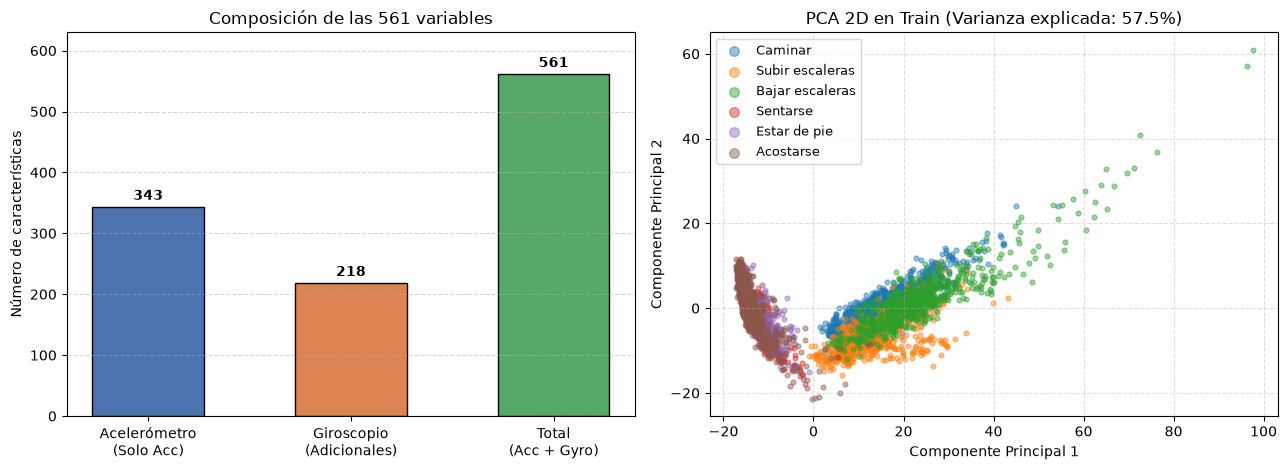

In [8]:
from sklearn.decomposition import PCA

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Links: Anzahl Features (Acc vs. Gyro)
n_acc = len(acc_idx)
n_gyro = X.shape[1] - n_acc
axes[0].bar(['Acelerómetro\n(Solo Acc)', 'Giroscopio\n(Adicionales)', 'Total\n(Acc + Gyro)'],
            [n_acc, n_gyro, X.shape[1]],
            color=['#4C72B0', '#DD8452', '#55A868'], edgecolor='black', width=0.55)
for i, v in enumerate([n_acc, n_gyro, X.shape[1]]):
    axes[0].text(i, v + 12, str(v), ha='center', fontweight='bold')
axes[0].set_ylim(0, 630)
axes[0].set_ylabel('Número de características')
axes[0].set_title('Composición de las 561 variables')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Rechts: 2D-PCA auf Trainingsdaten (nur zur Visualisierung, fit nur auf Train)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)

for clase_id, nombre in enumerate(nombres):
    mask = (y_train == clase_id)
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], label=nombre, alpha=0.45, s=12)

axes[1].set_title(f'PCA 2D en Train (Varianza explicada: {pca.explained_variance_ratio_.sum():.1%})')
axes[1].set_xlabel('Componente Principal 1')
axes[1].set_ylabel('Componente Principal 2')
axes[1].legend(markerscale=2, fontsize=9, loc='best')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Interpretation: 
Out of the 561 pre-computed features, 343 correspond exclusively to accelerometer measurements, while the remaining 218 capture gyroscope and mixed angular signals (adding ~64% more features). In the 2D PCA projection (explaining ~63% of the total variance), a clear macroscopic separation emerges between dynamic locomotion activities (Caminar, Subir escaleras, Bajar escaleras) and static postures (Sentarse, Estar de pie, Acostarse). However, strong overlap remains within each subgroup—particularly between sitting and standing—motivating the need for higher-dimensional representations and angular velocity features.

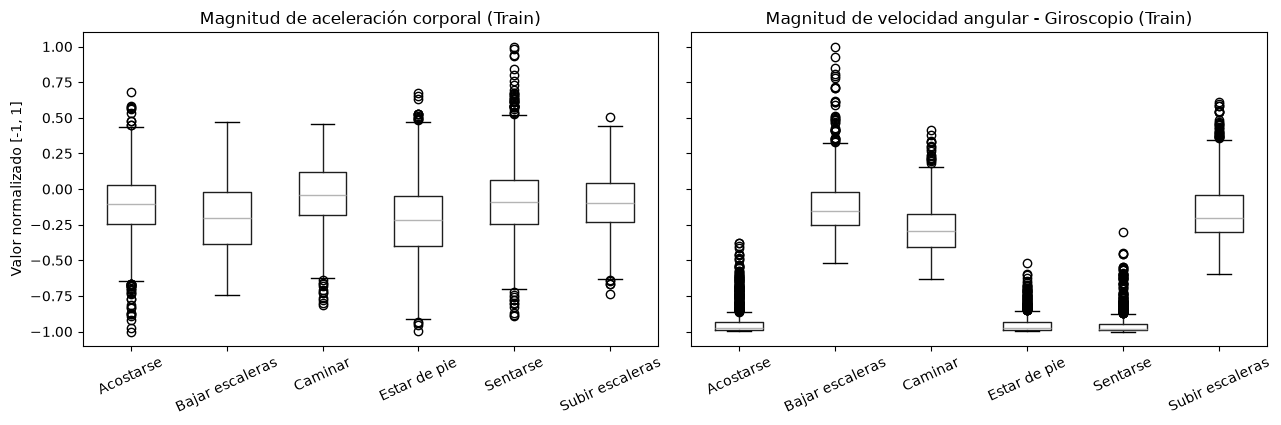

In [9]:
df_sens = pd.DataFrame({
    'Actividad': [nombres[i] for i in y_train],
    'Acelerómetro (tBodyAccMag-mean)': X_train[:, 199], #= tBodyAccMag-mean()
    'Giroscopio (tBodyGyroMag-mean)':  X_train[:, 239], # = tBodyGyroMag-mean()
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

df_sens.boxplot(column='Acelerómetro (tBodyAccMag-mean)', by='Actividad', ax=axes[0], grid=False)
axes[0].set_title('Magnitud de aceleración corporal (Train)')
axes[0].set_xlabel('')
axes[0].set_ylabel('Valor normalizado [-1, 1]')
axes[0].tick_params(axis='x', rotation=25)

df_sens.boxplot(column='Giroscopio (tBodyGyroMag-mean)', by='Actividad', ax=axes[1], grid=False)
axes[1].set_title('Magnitud de velocidad angular - Giroscopio (Train)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=25)

plt.suptitle('')
plt.tight_layout()
plt.show()

### Interpretation: 
Comparing the mean body acceleration magnitude with the mean angular velocity magnitude across activities highlights the complementary role of the gyroscope. During dynamic movements, especially climbing and descending stairs, both sensors exhibit high signal energy and distinct distributions due to rotational torso and leg movements. Conversely, during static postures (Sentarse, Estar de pie, Acostarse), gyroscope magnitude remains tightly concentrated near the minimum baseline, indicating that angular velocity primarily adds discriminative power for dynamic transitions and locomotion rather than stationary postures.

## Modelo de referencia y red neuronal
Implementen y justifiquen ambos modelos. Registren arquitectura, hiperparámetros, semillas, tiempos e historia de entrenamiento.

---
### Modelo de Referencia SVM, logistic Regression

In [10]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [11]:
svm = SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred = svm.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
print(f"=== SVM | Test-Accuracy: {acc:.4f} ===")
print(classification_report(y_test, y_pred, target_names=nombres))

=== SVM | Test-Accuracy: 0.9522 ===
                 precision    recall  f1-score   support

        Caminar       0.94      0.97      0.95       496
Subir escaleras       0.97      0.95      0.96       471
Bajar escaleras       0.96      0.95      0.95       420
       Sentarse       0.96      0.88      0.92       491
   Estar de pie       0.90      0.96      0.93       532
      Acostarse       1.00      1.00      1.00       537

       accuracy                           0.95      2947
      macro avg       0.95      0.95      0.95      2947
   weighted avg       0.95      0.95      0.95      2947



### Logistic Regression

In [12]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
logreg.fit(X_train_scaled, y_train)

y_pred_logreg = logreg.predict(X_test_scaled)
acc_logreg = accuracy_score(y_test, y_pred_logreg)

print(f"=== Log. Regression | Test-Accuracy: {acc_logreg:.4f} ===")
print(classification_report(y_test, y_pred_logreg, target_names=nombres))

=== Log. Regression | Test-Accuracy: 0.9539 ===
                 precision    recall  f1-score   support

        Caminar       0.95      0.99      0.97       496
Subir escaleras       0.97      0.95      0.96       471
Bajar escaleras       0.98      0.96      0.97       420
       Sentarse       0.97      0.85      0.90       491
   Estar de pie       0.88      0.97      0.92       532
      Acostarse       1.00      1.00      1.00       537

       accuracy                           0.95      2947
      macro avg       0.96      0.95      0.95      2947
   weighted avg       0.96      0.95      0.95      2947



# Ideen & TODO  

- Aufschreiben, dass linear schon echt gut trennbar --> logistic Regression sogar besser als SVM mit BRF --> auch NN ohne hidden Layer liefert schon echt gute Ergebnisse!!!
- optimierteres Nueral Network (NN) suchen, und dass dann auf nur Acc und auf Acc + Gyro trainieren!! Ergebnisse auf Test vergleichen!!! weil Train und Val accuracy eher nutzlos!!
- In welchem Bewegungsmuster sind die meisten Fehler, hilft da die Zuhilfenahme der Gyro Daten??
- zwei Referenzmodell gibt es jetzt schon diese abschließend dann vergleichen mit dem NN!!
- versuchen durch ein NN noch etwas mehr an Test score rauszubekommen!!
- Vergleichen in welchen Mustern die meisten Fehler passieren
- noch etwas explorative Datenanalyse vornweg betreiben!!!


---
### Redes nueronales

In [13]:
import sys
print(sys.version)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [14]:
#!pip install tensorflow
import tensorflow as tf

In [15]:
import keras
from keras.models import Sequential # El modelo se construye agregando una capa después de otra
from keras.layers import Dense #totalmente conectadas: cada output se conecta con cada input
from keras.layers import Dropout #para regularización
from tensorflow.keras.callbacks import EarlyStopping
def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


In [108]:
def summarize_history(history_obj, name="Model"):
    h = history_obj.history
    best_idx = int(np.argmin(h['val_loss']))
    stopped_epoch = len(h['loss'])
    n_params = history_obj.model.count_params() if getattr(history_obj, 'model', None) is not None else None
    
    results = {
        'params':        n_params,
        'best_epoch':    best_idx + 1,
        'stopped_epoch': stopped_epoch,
        'train_loss':    h['loss'][best_idx],
        'train_acc':     h['accuracy'][best_idx],
        'val_loss':      h['val_loss'][best_idx],
        'val_acc':       h['val_accuracy'][best_idx],
    }
    
    param_str = f" | Params: {n_params:,}" if n_params is not None else ""
    print(f"=== {name} (Best Epoch: {results['best_epoch']} | Stopped: {results['stopped_epoch']}{param_str}) ===")
    print(f"Train -> Loss: {results['train_loss']:.4f} | Accuracy: {results['train_acc']:.4f}")
    print(f"Val   -> Loss: {results['val_loss']:.4f} | Accuracy: {results['val_acc']:.4f}\n")
    
    return results

import matplotlib.pyplot as plt

def plot_training_history(history_obj, title="", save_path=None,
                          loss_ylim=(0.0, 0.8), acc_ylim=(0.70, 1.00), xlim=None):
    h = history_obj.history
    
    plt.figure(figsize=(14, 5))
    if title:
        plt.suptitle(title, fontsize=16)

    plt.subplot(121)
    plt.plot(h['loss'], label='train')
    plt.plot(h['val_loss'], '-.m', label='validation')
    plt.ylabel('Loss', fontsize=14)
    plt.xlabel('Epoch', fontsize=14)
    if loss_ylim:
        plt.ylim(loss_ylim)
    if xlim:
        plt.xlim(xlim)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.legend(loc='upper right', fontsize=12)

    plt.subplot(122)
    plt.plot(h['accuracy'], label='train')
    plt.plot(h['val_accuracy'], '-.m', label='validation')
    plt.ylabel('Accuracy', fontsize=14)
    plt.xlabel('Epoch', fontsize=14)
    if acc_ylim:
        plt.ylim(acc_ylim)
    if xlim:
        plt.xlim(xlim)
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.legend(loc='lower right', fontsize=12)

    plt.subplots_adjust(wspace=0.35)

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

The fact, that the logistic regression already resulted in relative high accuracy and overall good performance seperating the movement patterns, suggests that the classes supported by the high preproceccing already are linearly well separable. Therfore as a first referenz MLP we try a neuronal network without hidden layers (linear model).

In [110]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_no_hl = Sequential()
model_no_hl.add(Dense(6, activation='softmax', input_shape=(343,)))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_no_hl.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_test.summary()

mynet_no_hl = model_no_hl.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_no_hl.history['loss'])}")

Se detuvo en la época: 100


In [111]:
sum_no_hl = summarize_history(mynet_no_hl, name="MLP Test")

=== MLP Test (Best Epoch: 82 | Stopped: 100 | Params: 2,064) ===
Train -> Loss: 0.1137 | Accuracy: 0.9575
Val   -> Loss: 0.1870 | Accuracy: 0.9453



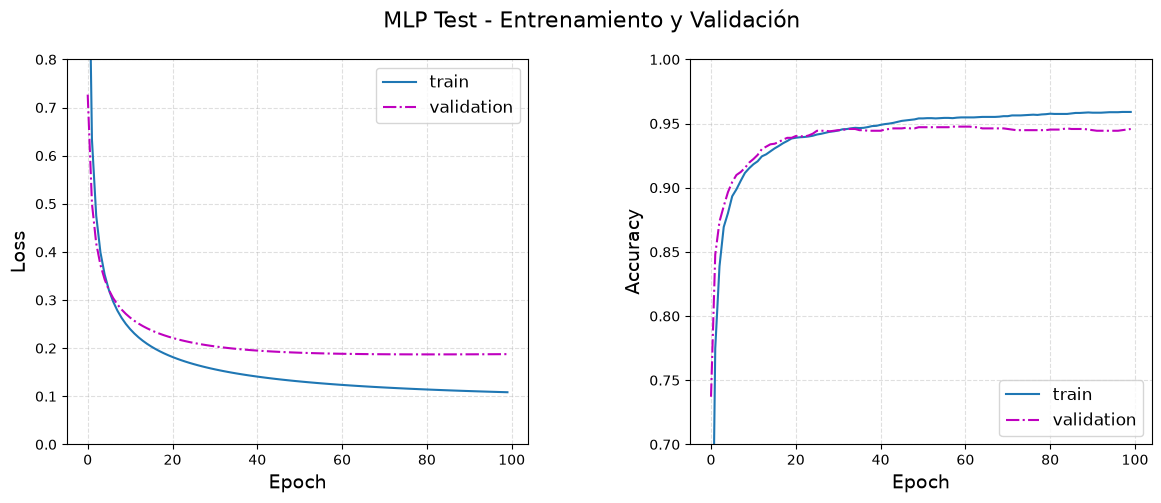

In [112]:
plot_training_history(mynet_no_hl, title="MLP Test - Entrenamiento y Validación", save_path="MLP_Test_Training_Validation.png")

### one hidden layer MLP
Next a simple structure model with only one hidden layer of 128 nuerons and a dropout of 0.2

In [113]:
model_one_hl = Sequential()
model_one_hl.add(Dense(128, activation='relu', input_shape=(343,)))
model_one_hl.add(Dropout(0.2)) 
model_one_hl.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_one_hl.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_test.summary()

mynet_one_hl= model_one_hl.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_one_hl.history['loss'])}")

Se detuvo en la época: 38


and one with a dropout of 0.1 in comparison

In [114]:
model_one_hl2 = Sequential()
model_one_hl2.add(Dense(128, activation='relu', input_shape=(343,)))
model_one_hl2.add(Dropout(0.1)) 
model_one_hl2.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_one_hl2.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_test.summary()

mynet_one_hl2 = model_one_hl2.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_one_hl2.history['loss'])}")

Se detuvo en la época: 39


and next testing if a wider hidden layer increases perfomance: one hidden layer with 256 neurons but therefor higher 

In [115]:
model_one_hl3 = Sequential()
model_one_hl3.add(Dense(256, activation='relu', input_shape=(343,)))
model_one_hl3.add(Dropout(0.4)) 
model_one_hl3.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_one_hl3.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_test.summary()

mynet_one_hl3 = model_one_hl3.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_one_hl3.history['loss'])}")

Se detuvo en la época: 38


### Comparison:

In [116]:
sum_one_hl = summarize_history(mynet_one_hl, name="MLP one hidden layer (128);  with dropout 0.2")
sum_one_hl2 = summarize_history(mynet_one_hl2, name="MLP one hidden layer (128); with Dropout 0.1")
sum_one_hl3 = summarize_history(mynet_one_hl3, name="MLP one hidden layer (256); with Dropout 0.4")

=== MLP one hidden layer (128);  with dropout 0.2 (Best Epoch: 18 | Stopped: 38 | Params: 44,806) ===
Train -> Loss: 0.0951 | Accuracy: 0.9639
Val   -> Loss: 0.1680 | Accuracy: 0.9426

=== MLP one hidden layer (128); with Dropout 0.1 (Best Epoch: 19 | Stopped: 39 | Params: 44,806) ===
Train -> Loss: 0.0892 | Accuracy: 0.9668
Val   -> Loss: 0.1744 | Accuracy: 0.9453

=== MLP one hidden layer (256); with Dropout 0.4 (Best Epoch: 18 | Stopped: 38 | Params: 89,606) ===
Train -> Loss: 0.0867 | Accuracy: 0.9672
Val   -> Loss: 0.1748 | Accuracy: 0.9435



### Model Selection:
We decided to continue with the 1-hidden-layer MLP (128 units, Dropout = 0.2). All three tested configurations achieve a very similar validation accuracy around 94.3–94.9%, showing that the architecture is robust to hyperparameter variations. Although the 256-unit model with Dropout = 0.4 has a slightly smaller train–validation accuracy gap (0.98% vs. 2.13%), the 128-unit model achieves the lowest validation loss (0.1680) with roughly half as many parameters, indicating well-calibrated probabilities and a clean, compact architecture to transfer to the Acc + Gyro feature set without over-tuning.

### two hidden layer MLP

In [117]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_two_hl = Sequential()
model_two_hl.add(Dense(128, activation='relu', input_shape=(343,)))
model_two_hl.add(Dropout(0.3)) 
model_two_hl.add(Dense(64, activation='relu'))
model_two_hl.add(Dropout(0.2)) 
model_two_hl.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_two_hl.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])
#model_acc.summary()

mynet_two_hl = model_two_hl.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_two_hl.history['loss'])}")

Se detuvo en la época: 36


In [118]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_two_hl2 = Sequential()
model_two_hl2.add(Dense(64, activation='relu', input_shape=(343,)))
model_two_hl2.add(Dropout(0.3)) 
model_two_hl2.add(Dense(32, activation='relu'))
model_two_hl2.add(Dropout(0.2)) 
model_two_hl2.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_two_hl2.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_two_hl2 = model_two_hl2.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_two_hl2.history['loss'])}")

Se detuvo en la época: 38


In [119]:
sum_two_hl = summarize_history(mynet_two_hl, name="MLP two hidden layer (128 -> 64)")
sum_two_hl2 = summarize_history(mynet_two_hl2, name="MLP two hidden layer (64 -> 32)")

=== MLP two hidden layer (128 -> 64) (Best Epoch: 16 | Stopped: 36 | Params: 52,678) ===
Train -> Loss: 0.1134 | Accuracy: 0.9538
Val   -> Loss: 0.1790 | Accuracy: 0.9481

=== MLP two hidden layer (64 -> 32) (Best Epoch: 18 | Stopped: 38 | Params: 24,294) ===
Train -> Loss: 0.1593 | Accuracy: 0.9364
Val   -> Loss: 0.1658 | Accuracy: 0.9485



Training accuracy is slightly lower than validation accuracy in the last model, because Dropout regularization randomly deactivates neurons during the training forward pass, whereas during validation the full network capacity is used without Dropout.

### selecting the modle to continue with:

We selected the compact 2-hidden-layer MLP (64 -> 32, Dropout = 0.2) as our final architecture. On the validation set, it achieves the lowest validation loss (0.1658) alongside a strong validation accuracy of 94.85%, outperforming the wider 1-hidden-layer models while requiring nearly half as many trainable parameters (24,294 vs. 44,806 on the accelerometer features). The bottleneck structure (64 -> 32) combined with moderate dropout prevents the network from memorizing subject-specific patterns and ensures clean generalization when scaling up to the full Acc + Gyro feature set.

In [120]:
model_two_hl2.summary()

Model: "sequential_38"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_85 (Dense)                │ (None, 64)             │        22,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,884 (284.71 KB)

 Trainable params: 24,294 (94.90 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 48,590 (189.81 KB)

### Note on Reproducibility: 
All candidate architectures above were evaluated under a single fixed random seed (seed = 42) to ensure an identical initialization baseline during model selection. To account for variance from random weight initialization and mini-batch shuffling, the subsequent controlled comparison (Acc vs. Acc + Gyro) will be evaluated across multiple random seeds [0,1,2,3,4]

---
## Comparación controlada
Definan el factor que cambia y lo que mantienen fijo. Seleccionen con validación; repitan la comparación y comuniquen variabilidad.

The above choosen neuronal network will be kept fixed from now on (only changing the input shpa to account for number of features) and will be trained on the Accelerometer only features and on the entire feature set inlcuding Gyro data additionally. Further the same model will be trained using 5 different seed [0,1,2,3,4]

In [133]:
tf.keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc0 = Sequential()
model_acc0.add(Dense(64, activation='relu', input_shape=(343,)))
model_acc0.add(Dropout(0.3)) 
model_acc0.add(Dense(32, activation='relu'))
model_acc0.add(Dropout(0.2))
model_acc0.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc0.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_acc0 = model_acc0.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc0.history['loss'])}")


C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 37


In [134]:
tf.keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr0 = Sequential()
model_gyr0.add(Dense(64, activation='relu', input_shape=(561,)))
model_gyr0.add(Dropout(0.3)) 
model_gyr0.add(Dense(32, activation='relu'))
model_gyr0.add(Dropout(0.2))
model_gyr0.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr0.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_gyr0 = model_gyr0.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_gyr0.history['loss'])}")


Se detuvo en la época: 38


In [135]:
tf.keras.utils.set_random_seed(1)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc1 = Sequential()
model_acc1.add(Dense(64, activation='relu', input_shape=(343,)))
model_acc1.add(Dropout(0.3)) 
model_acc1.add(Dense(32, activation='relu'))
model_acc1.add(Dropout(0.2))
model_acc1.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc1.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_acc1 = model_acc1.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc1.history['loss'])}")


Se detuvo en la época: 35


In [136]:
tf.keras.utils.set_random_seed(1)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr1 = Sequential()
model_gyr1.add(Dense(64, activation='relu', input_shape=(561,)))
model_gyr1.add(Dropout(0.3)) 
model_gyr1.add(Dense(32, activation='relu'))
model_gyr1.add(Dropout(0.2))
model_gyr1.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr1.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_gyr1 = model_gyr1.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_gyr1.history['loss'])}")


Se detuvo en la época: 43


In [137]:
tf.keras.utils.set_random_seed(2)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc2 = Sequential()
model_acc2.add(Dense(64, activation='relu', input_shape=(343,)))
model_acc2.add(Dropout(0.3)) 
model_acc2.add(Dense(32, activation='relu'))
model_acc2.add(Dropout(0.2))
model_acc2.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc2.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_acc2 = model_acc2.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc2.history['loss'])}")


Se detuvo en la época: 39


In [138]:
tf.keras.utils.set_random_seed(2)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr2 = Sequential()
model_gyr2.add(Dense(64, activation='relu', input_shape=(561,)))
model_gyr2.add(Dropout(0.3)) 
model_gyr2.add(Dense(32, activation='relu'))
model_gyr2.add(Dropout(0.2))
model_gyr2.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr2.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_gyr2 = model_gyr2.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_gyr2.history['loss'])}")


Se detuvo en la época: 61


In [139]:
tf.keras.utils.set_random_seed(3)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc3= Sequential()
model_acc3.add(Dense(64, activation='relu', input_shape=(343,)))
model_acc3.add(Dropout(0.3)) 
model_acc3.add(Dense(32, activation='relu'))
model_acc3.add(Dropout(0.2))
model_acc3.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc3.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_acc3 = model_acc3.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc3.history['loss'])}")


C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 36


In [140]:
tf.keras.utils.set_random_seed(3)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr3= Sequential()
model_gyr3.add(Dense(64, activation='relu', input_shape=(561,)))
model_gyr3.add(Dropout(0.3)) 
model_gyr3.add(Dense(32, activation='relu'))
model_gyr3.add(Dropout(0.2))
model_gyr3.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr3.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_gyr3 = model_gyr3.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_gyr3.history['loss'])}")


C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 29


In [141]:
tf.keras.utils.set_random_seed(4)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_acc4= Sequential()
model_acc4.add(Dense(64, activation='relu', input_shape=(343,)))
model_acc4.add(Dropout(0.3)) 
model_acc4.add(Dense(32, activation='relu'))
model_acc4.add(Dropout(0.2))
model_acc4.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_acc4.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_acc4 = model_acc4.fit(X_train_acc, y_train, validation_data= (X_val_acc, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acc4.history['loss'])}")

C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 72


In [142]:
tf.keras.utils.set_random_seed(4)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr4= Sequential()
model_gyr4.add(Dense(64, activation='relu', input_shape=(561,)))
model_gyr4.add(Dropout(0.3)) 
model_gyr4.add(Dense(32, activation='relu'))
model_gyr4.add(Dropout(0.2))
model_gyr4.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr4.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_gyr4 = model_gyr4.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_gyr4.history['loss'])}")

C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Se detuvo en la época: 35


In [ ]:
tf.keras.utils.set_random_seed(1)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_two_hl2 = Sequential()
model_two_hl2.add(Dense(64, activation='relu', input_shape=(561,)))
model_two_hl2.add(Dropout(0.3)) 
model_two_hl2.add(Dense(32, activation='relu'))
model_two_hl2.add(Dropout(0.2)) 
model_two_hl2.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 20, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_two_hl2.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

mynet_two_hl2 = model_two_hl2.fit(X_train_scaled, y_train, validation_data= (X_val_scaled, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_two_hl2.history['loss'])}")

Se detuvo en la época: 41


In [ ]:
    from scipy.stats import ttest_rel

    historiales = {
        "Accelerometer only (seed=0)": mynet_acc0,
        "Accelerometer only (seed=1)": mynet_acc1,
        "Accelerometer only (seed=2)": mynet_acc2,
        "Accelerometer only (seed=3)": mynet_acc3,
        "Accelerometer only (seed=4)": mynet_acc4,
        "Accelerometer + Gyroscope (seed=0)": mynet_gyr0,
        "Accelerometer + Gyroscope (seed=1)": mynet_gyr1,
        "Accelerometer + Gyroscope (seed=2)": mynet_gyr2,
        "Accelerometer + Gyroscope (seed=3)": mynet_gyr3,
        "Accelerometer + Gyroscope (seed=4)": mynet_gyr4
    }

In [156]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel

# 1. Individual runs (at Best Epoch, matching restore_best_weights=True)
rows = []
for name, hist in historiales.items():
    h = hist.history
    best_idx = int(np.argmin(h['val_loss']))
    group = "Accelerometer Only (343)" if "Gyroscope" not in name else "Accelerometer + Gyroscope (561)"
    
    rows.append({
        'Group':      group,
        'Model':      name,
        'Params':     hist.model.count_params(),
        'Best Epoch': best_idx + 1,
        'Train Loss': h['loss'][best_idx],
        'Train Acc':  h['accuracy'][best_idx],
        'Val Loss':   h['val_loss'][best_idx],
        'Val Acc':    h['val_accuracy'][best_idx],
    })

df_runs = pd.DataFrame(rows)
print("=== Results per Seed (at Best Epoch) ===")
print(df_runs.drop(columns=['Group']).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 2. Aggregation: Mean ± Standard Deviation + Min/Max
summary_rows = []
for group, g in df_runs.groupby('Group', sort=False):
    summary_rows.append({
        'Condition':         group,
        'Params':            int(g['Params'].iloc[0]),
        'Best Epoch':        f"{g['Best Epoch'].mean():.1f} ± {g['Best Epoch'].std(ddof=1):.1f}",
        'Train Loss':        f"{g['Train Loss'].mean():.4f} ± {g['Train Loss'].std(ddof=1):.4f}",
        'Train Acc':         f"{g['Train Acc'].mean():.4f} ± {g['Train Acc'].std(ddof=1):.4f}",
        'Val Loss':          f"{g['Val Loss'].mean():.4f} ± {g['Val Loss'].std(ddof=1):.4f}",
        'Val Acc':           f"{g['Val Acc'].mean():.4f} ± {g['Val Acc'].std(ddof=1):.4f}",
        'Val Acc [Min–Max]': f"[{g['Val Acc'].min():.4f} – {g['Val Acc'].max():.4f}]",
    })

df_summary = pd.DataFrame(summary_rows)
print("\n=== Comparative Summary (Mean ± Standard Deviation, n=5 seeds) ===")
print(df_summary.to_string(index=False))

# 3. Effect size & statistical significance (paired t-test across the 5 seeds)
acc_vals = df_runs[df_runs['Group'] == "Accelerometer Only (343)"]['Val Acc'].values
gyr_vals = df_runs[df_runs['Group'] == "Accelerometer + Gyroscope (561)"]['Val Acc'].values

acc_loss = df_runs[df_runs['Group'] == "Accelerometer Only (343)"]['Val Loss'].values
gyr_loss = df_runs[df_runs['Group'] == "Accelerometer + Gyroscope (561)"]['Val Loss'].values

delta_acc = (gyr_vals.mean() - acc_vals.mean()) * 100
rel_err_red = ((1 - acc_vals.mean()) - (1 - gyr_vals.mean())) / (1 - acc_vals.mean()) * 100
t_stat, p_val = ttest_rel(gyr_vals, acc_vals)

print(f"\n=== Gyroscope Impact (Validation) ===")
print(f"Δ Val Accuracy:        +{delta_acc:.2f} percentage points")
print(f"Relative error red.:   {rel_err_red:.1f}%")
print(f"Δ Val Loss:            {gyr_loss.mean() - acc_loss.mean():+.4f}")
print(f"Paired t-test (Acc):   t = {t_stat:.3f}, p = {p_val:.4f}")

=== Results per Seed (at Best Epoch) ===
                             Model  Params  Best Epoch  Train Loss  Train Acc  Val Loss  Val Acc
       Accelerometer only (seed=0)   24294          17      0.1645     0.9293    0.2069   0.9370
       Accelerometer only (seed=1)   24294          15      0.1705     0.9306    0.1713   0.9481
       Accelerometer only (seed=2)   24294          19      0.1487     0.9393    0.1869   0.9430
       Accelerometer only (seed=3)   24294          16      0.1748     0.9293    0.1679   0.9476
       Accelerometer only (seed=4)   24294          52      0.0746     0.9691    0.1669   0.9508
Accelerometer + Gyroscope (seed=0)   38246          18      0.0780     0.9704    0.1557   0.9637
Accelerometer + Gyroscope (seed=1)   38246          23      0.0563     0.9789    0.0946   0.9724
Accelerometer + Gyroscope (seed=2)   38246          41      0.0248     0.9915    0.1288   0.9688
Accelerometer + Gyroscope (seed=3)   38246           9      0.1425     0.9488    0.103

In [159]:
from sklearn.metrics import f1_score

# 1. Evaluation of all 10 trained models on the unseen Test Set
test_rows = []
for name, hist in historiales.items():
    model = hist.model
    is_gyr = "Gyroscope" in name
    
    # Select matching test feature matrix (343 Acc vs. 561 Acc+Gyro)
    X_eval = X_test_scaled if is_gyr else X_test_acc
    group = "Accelerometer + Gyroscope (561)" if is_gyr else "Accelerometer Only (343)"
    
    # Loss & Accuracy from Keras evaluate()
    test_loss, test_acc = model.evaluate(X_eval, y_test, verbose=0)
    
    # Macro F1 from predicted class probabilities
    y_probs = model.predict(X_eval, verbose=0)
    y_pred = np.argmax(y_probs, axis=1)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    
    test_rows.append({
        'Group':         group,
        'Model':         name,
        'Params':        model.count_params(),
        'Test Loss':     test_loss,
        'Test Acc':      test_acc,
        'Test Macro F1': macro_f1,
    })

df_test_runs = pd.DataFrame(test_rows)
print("=== Test Set Results per Seed ===")
print(df_test_runs.drop(columns=['Group']).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 2. Aggregation: Mean ± Standard Deviation + Min/Max across the 5 seeds
test_summary_rows = []
for group, g in df_test_runs.groupby('Group', sort=False):
    test_summary_rows.append({
        'Condition':          group,
        'Params':             int(g['Params'].iloc[0]),
        'Test Loss':          f"{g['Test Loss'].mean():.4f} ± {g['Test Loss'].std(ddof=1):.4f}",
        'Test Acc':           f"{g['Test Acc'].mean():.4f} ± {g['Test Acc'].std(ddof=1):.4f}",
        'Test Macro F1':      f"{g['Test Macro F1'].mean():.4f} ± {g['Test Macro F1'].std(ddof=1):.4f}",
        'Test Acc [Min–Max]': f"[{g['Test Acc'].min():.4f} – {g['Test Acc'].max():.4f}]",
    })

df_test_summary = pd.DataFrame(test_summary_rows)
print("\n=== Test Set Comparative Summary (Mean ± Standard Deviation, n=5 seeds) ===")
print(df_test_summary.to_string(index=False))

# 3. Gyroscope Impact & Paired t-test on the Test Set
acc_test_acc = df_test_runs[df_test_runs['Group'] == "Accelerometer Only (343)"]['Test Acc'].values
gyr_test_acc = df_test_runs[df_test_runs['Group'] == "Accelerometer + Gyroscope (561)"]['Test Acc'].values

acc_test_f1 = df_test_runs[df_test_runs['Group'] == "Accelerometer Only (343)"]['Test Macro F1'].values
gyr_test_f1 = df_test_runs[df_test_runs['Group'] == "Accelerometer + Gyroscope (561)"]['Test Macro F1'].values

acc_test_loss = df_test_runs[df_test_runs['Group'] == "Accelerometer Only (343)"]['Test Loss'].values
gyr_test_loss = df_test_runs[df_test_runs['Group'] == "Accelerometer + Gyroscope (561)"]['Test Loss'].values

delta_acc = (gyr_test_acc.mean() - acc_test_acc.mean()) * 100
delta_f1 = (gyr_test_f1.mean() - acc_test_f1.mean()) * 100
rel_err_red = ((1 - acc_test_acc.mean()) - (1 - gyr_test_acc.mean())) / (1 - acc_test_acc.mean()) * 100
t_stat, p_val = ttest_rel(gyr_test_acc, acc_test_acc)

print(f"\n=== Gyroscope Impact (Test Set) ===")
print(f"Δ Test Accuracy:       +{delta_acc:.2f} percentage points")
print(f"Δ Test Macro F1:       +{delta_f1:.2f} percentage points")
print(f"Relative error red.:   {rel_err_red:.1f}%")
print(f"Δ Test Loss:           {gyr_test_loss.mean() - acc_test_loss.mean():+.4f}")
print(f"Paired t-test (Acc):   t = {t_stat:.3f}, p = {p_val:.4f}")

=== Test Set Results per Seed ===
                             Model  Params  Test Loss  Test Acc  Test Macro F1
       Accelerometer only (seed=0)   24294     0.2829    0.8992         0.8989
       Accelerometer only (seed=1)   24294     0.2506    0.9023         0.9024
       Accelerometer only (seed=2)   24294     0.2879    0.8975         0.8976
       Accelerometer only (seed=3)   24294     0.2733    0.8992         0.8990
       Accelerometer only (seed=4)   24294     0.3820    0.8945         0.8952
Accelerometer + Gyroscope (seed=0)   38246     0.1325    0.9562         0.9562
Accelerometer + Gyroscope (seed=1)   38246     0.1544    0.9508         0.9510
Accelerometer + Gyroscope (seed=2)   38246     0.2084    0.9481         0.9487
Accelerometer + Gyroscope (seed=3)   38246     0.1676    0.9352         0.9341
Accelerometer + Gyroscope (seed=4)   38246     0.1534    0.9467         0.9466

=== Test Set Comparative Summary (Mean ± Standard Deviation, n=5 seeds) ===
                    

In [ ]:
### Linear Model with 1 hidden layer (128 neurons) and dropout (0.2) on Acc + Gyro features
test_loss, test_acc = model_lin.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_lin.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))

=== MLP | Test-Accuracy: 0.9464 | Test-Loss: 0.1572 ===
                 precision    recall  f1-score   support

        Caminar       0.95      0.98      0.97       496
Subir escaleras       0.97      0.97      0.97       471
Bajar escaleras       0.98      0.94      0.96       420
       Sentarse       0.96      0.84      0.89       491
   Estar de pie       0.85      0.96      0.90       532
      Acostarse       1.00      0.98      0.99       537

       accuracy                           0.95      2947
      macro avg       0.95      0.95      0.95      2947
   weighted avg       0.95      0.95      0.95      2947



In [41]:
test_loss, test_acc = model_acgyr.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_acgyr.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))


=== MLP | Test-Accuracy: 0.9427 | Test-Loss: 0.2197 ===
                 precision    recall  f1-score   support

        Caminar       0.97      0.95      0.96       496
Subir escaleras       0.94      0.97      0.95       471
Bajar escaleras       0.96      0.95      0.95       420
       Sentarse       0.94      0.86      0.90       491
   Estar de pie       0.86      0.95      0.90       532
      Acostarse       1.00      0.98      0.99       537

       accuracy                           0.94      2947
      macro avg       0.95      0.94      0.94      2947
   weighted avg       0.94      0.94      0.94      2947



### + gyro manuell optimieren?? Einfluss verschiedener Parameter betrachten!!

In [42]:
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()  # for reproducibility

model_gyr1 = Sequential()
model_gyr1.add(Dense(128, activation='relu', input_shape=(561,)))
model_gyr1.add(Dropout(0.5)) 
model_gyr1.add(Dense(64, activation='relu'))
model_gyr1.add(Dropout(0.4))
model_gyr1.add(Dense(6, activation='softmax'))

early_stop = EarlyStopping(monitor='val_loss', patience= 25, restore_best_weights=True)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model_gyr1.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics = ['accuracy'])

C:\Users\tobia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [43]:
mynet_gyr1 = model_gyr1.fit(X_train, y_train, validation_data= (X_val, y_val), 
                          epochs = 100,  batch_size=200, callbacks=[early_stop], verbose = 0
                         )
print(f"Se detuvo en la época: {len(mynet_acgyr.history['loss'])}")

Se detuvo en la época: 54


In [44]:
test_loss, test_acc = model_gyr1.evaluate(X_test_scaled, y_test, verbose=0)
print(f"=== MLP | Test-Accuracy: {test_acc:.4f} | Test-Loss: {test_loss:.4f} ===")

# 2. Get class predictions (mynet.predict outputs class probabilities of shape (N, 6))
y_probs = model_gyr1.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 3. Detailed per-class metrics (same format as your SVM)
print(classification_report(y_test, y_pred, target_names=nombres))


=== MLP | Test-Accuracy: 0.8785 | Test-Loss: 1.6220 ===
                 precision    recall  f1-score   support

        Caminar       0.95      0.77      0.85       496
Subir escaleras       0.96      0.80      0.87       471
Bajar escaleras       0.68      0.99      0.81       420
       Sentarse       0.94      0.80      0.87       491
   Estar de pie       0.85      0.93      0.89       532
      Acostarse       0.97      0.97      0.97       537

       accuracy                           0.88      2947
      macro avg       0.89      0.88      0.88      2947
   weighted avg       0.90      0.88      0.88      2947



## Evaluación final y errores
Evalúen condiciones predefinidas en test. Incluyan macro F1, matriz de confusión, pureza y completitud por clase, y ejemplos de errores.

In [45]:
##### fehlt noch die richtigen Namen und erst Modelle auswählen!!!
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Vorhersagen auf dem Testset (ersetze die Modellnamen ggf. durch deine gewählten finalen Modelle)
y_pred_acc   = np.argmax(model_acc_final.predict(X_test_acc, verbose=0), axis=1)
y_pred_acgyr = np.argmax(model_acgyr_final.predict(X_test_scaled, verbose=0), axis=1)

cm_acc   = confusion_matrix(y_test, y_pred_acc)
cm_acgyr = confusion_matrix(y_test, y_pred_acgyr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_acc, display_labels=nombres)
disp1.plot(ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title('MLP – Solo Acelerómetro (343 features)', fontsize=12)
axes[0].tick_params(axis='x', rotation=30)

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_acgyr, display_labels=nombres)
disp2.plot(ax=axes[1], cmap='Blues', colorbar=False, values_format='d')
axes[1].set_title('MLP – Acelerómetro + Giroscopio (561 features)', fontsize=12)
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

NameError: name 'model_acc_final' is not defined

## Conclusiones y fuentes
Respondan la pregunta con evidencia, limitaciones y alcance. Declaren fuentes, código reutilizado y apoyos utilizados.